# BUSI2066 · Week 10 — A Number Across Groups: t-test and ANOVA


### Before you start

Drag in **this notebook** and **`segments.csv`** (the same file as last week), and select the kernel.

### Today

Week 8: two numbers. Week 9: two categories. Today: **one number, one category** — the most common
shape of research question in a customer survey.

We will load and inspect the dataset first, then state the three research questions below.

You described this in week 5 with `groupby` and a box plot. Today you **test** it.

### The rule

> **AI explains. It does not write**.

---
# Part 0 · Set up

In [25]:
%pip install -q pandas seaborn scipy statsmodels


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('segments.csv')
print(df.shape)
df.head()

(300, 7)


,age,gender,income,kids,ownHome,subscribe,Segment
0,47.316133,Male,49482.810438,2,ownNo,subNo,Suburb mix
1,31.386839,Male,35546.288300,1,ownYes,subNo,Suburb mix
2,43.200342,Male,44169.186377,0,ownYes,subNo,Suburb mix
3,37.316995,Female,81041.986385,1,ownNo,subNo,Suburb mix
4,40.954390,Female,79353.014443,3,ownYes,subNo,Suburb mix


Same 300 customers as last week. ⚠️ Still simulated — and the negative income in `describe()` is
still there. A real analyst would investigate that before anything else. Today we are learning the
tests, so we note it and move on; in your own data you would not.

Three research questions:

| RQ | Question | Groups | Test |
|---|---|---|---|
| **RQ1** | Is income related to home ownership? | 2 | two-sample t-test |
| **RQ2** | Is income related to segment? | 4 | one-way ANOVA |
| **RQ3** | Is income related to both at once? | 2 × 4 | two-way ANOVA |

---
# Part 1 · Describe first — always

## 1.1 One grouping column

This is week 5's `groupby`, with `.agg()` to get several summaries at once.

In [27]:
df.groupby('ownHome')['income'].agg(['count', 'mean', 'median', 'std']).round(0)

,count,mean,median,std
ownHome,,,,
ownNo,159,47391.0,51413.0,18939.0
ownYes,141,54935.0,52953.0,20758.0


Owners average **54,935**, non-owners **47,391** — a gap of about 7,500. But the **medians** are much
closer (52,953 and 51,413): some low incomes pull the non-owners' mean down. Both groups are large
(141 and 159). Owners spread a little more (SD 20,758 vs 18,939), but the spreads are close.
The gap, the spread and the n are what a t-test weighs.

`.agg([...])` takes a list of summaries and gives you a proper table. Always include `count`.

In [28]:
df.groupby('Segment')['income'].agg(['count', 'mean', 'std']).round(0)

,count,mean,std
Segment,,,
Moving up,70,53091.0,9637.0
Suburb mix,100,55034.0,11948.0
Travelers,80,62214.0,23752.0
Urban hip,50,21682.0,4887.0


Four segments, and one of them — **Urban hip, 21,682** — is nowhere near the other three. If income
is related to segment, that group is the reason.

## 1.2 Two grouping columns at once

Give `groupby` a **list** of two columns and it splits by every combination.

In [29]:
df.groupby(['Segment', 'ownHome'])['income'].mean().round(0)

Segment     ownHome
Moving up   ownNo      54498.0
            ownYes     50216.0
Suburb mix  ownNo      54933.0
            ownYes     55143.0
Travelers   ownNo      63188.0
            ownYes     61889.0
Urban hip   ownNo      21338.0
            ownYes     23059.0
Name: income, dtype: float64

Eight means, one per segment-and-ownership combination. Read down the pairs: within every segment,
owners and non-owners earn about the same. **The ownership gap you saw in §1.1 disappears once you
look inside segments.** Hold that thought — it is the whole of Part 4.

## 1.3 Draw it — one bar per group

Week 5's `barplot` draws the **mean** of `y` for each group. First by ownership, then by segment.
`order=` sets the order of the bars — here lowest mean to highest.

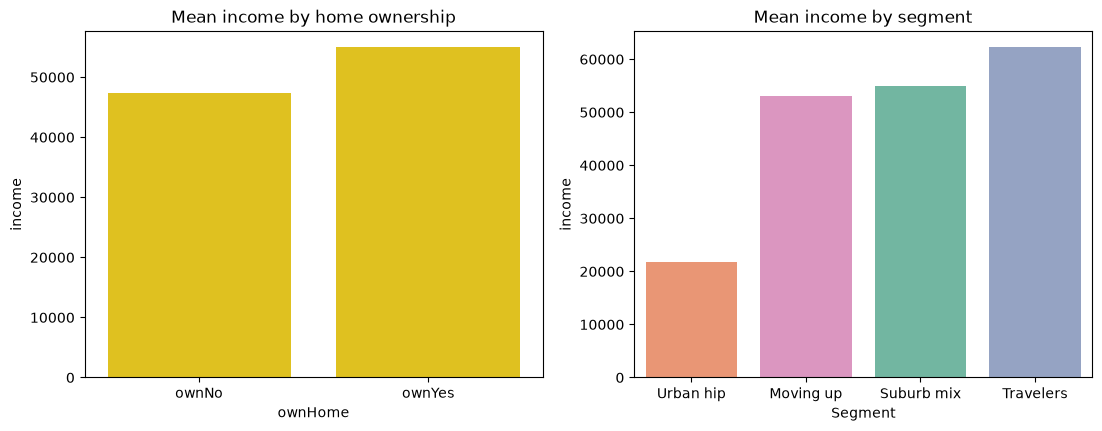

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df, x='ownHome', y='income', errorbar=None, color='gold', ax=axes[0])
axes[0].set_title('Mean income by home ownership')

sns.barplot(data=df, x='Segment', y='income', errorbar=None, hue='Segment', palette='Set2',
            order=['Urban hip', 'Moving up', 'Suburb mix', 'Travelers'], ax=axes[1])
axes[1].set_title('Mean income by segment')

plt.show()

**One bar is one number.** The bars show the means from §1.1 — but not how spread out each group is.
The box plot does that.

## 1.4 The box plot, and the two-way means

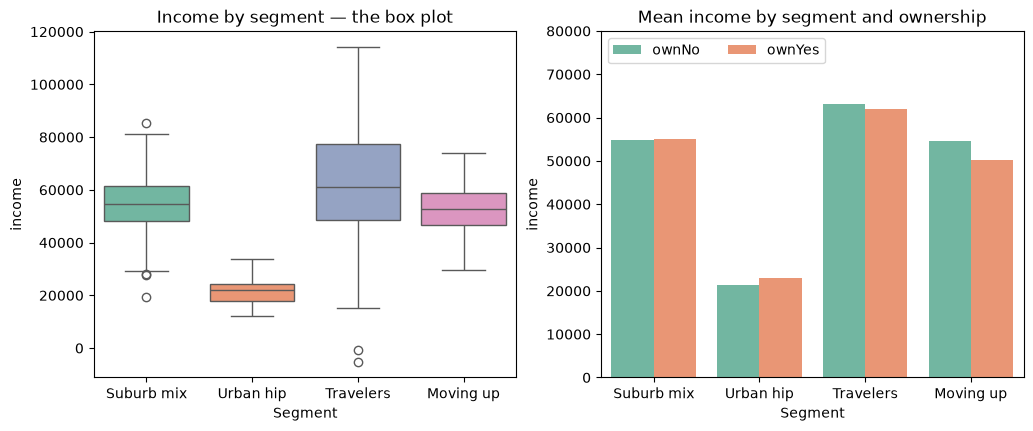

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x='Segment', y='income', hue='Segment', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Income by segment — the box plot')

sns.barplot(data=df, x='Segment', y='income', hue='ownHome', palette='Set2', errorbar=None, ax=axes[1])
axes[1].set_title('Mean income by segment and ownership')
axes[1].set_ylim(0, 80000)
axes[1].legend(loc='upper left', ncol=2)

plt.show()

Left: the week-5 rule — box plot to **look**. Urban hip is visibly lower and tighter. Right: `barplot`
with `hue='ownHome'` draws the two-way means from §1.2 as **dodged bars**, and you can see the
within-segment pairs are close —
and in two segments owners earn slightly less.

📖 `set_ylim(0, 80000)` makes room at the top, and `legend(loc='upper left', ncol=2)` puts the legend
there in one row, so it does not cover the bars.

---
# Part 2 · Two groups — the two-sample t-test

| | |
|---|---|
| **H₀** | Mean income is the **same** for owners and non-owners |
| **H₁** | It is different — in either direction (**two-sided**) |

Week 6's `ttest_1samp` compared one sample to a number. `ttest_ind` compares **two independent
samples** to each other — and to give it two samples, you have to **filter rows**, which is new.

## 2.0 How many groups? — `unique()` picks the test

Week 5's `unique()` lists each value once. Count them: **two groups → t-test**, three or more → ANOVA.

In [32]:
print(df['ownHome'].unique())      # 2 values -> two-sample t-test
print(df['Segment'].unique())      # 4 values -> one-way ANOVA (Part 3)

<StringArray>
['ownNo', 'ownYes']
Length: 2, dtype: str
<StringArray>
['Suburb mix', 'Urban hip', 'Travelers', 'Moving up']
Length: 4, dtype: str


**What the t-test compares.** H₀ says the two **population** means are the same. The test divides the
gap between the two sample means by its **standard error** — and the standard error is small when the
groups are big and not very spread out (week 6). That ratio is **t**. A big t gives a small p: a gap
that size is hard to explain by chance. The slides draw it.

## 2.1 Filtering rows — the first time in this course

In [33]:
owners = df.loc[df['ownHome'] == 'ownYes', 'income']
renters = df.loc[df['ownHome'] == 'ownNo', 'income']

print(len(owners), len(renters))
print(owners.mean(), renters.mean())

141 159
54934.683309139094 47391.009487409814


Read `df.loc[condition, column]` as: **rows where** the condition is true, **column** income.

- `df['ownHome'] == 'ownYes'` is a question asked of every row — 300 answers, `True` or `False`
- `.loc[that, 'income']` keeps only the `True` rows, and hands you their income

Two Series: 141 owner incomes and 159 non-owner incomes. **This is the idiom for "the values of
this column, for this group".** You will use it again whenever you compare two groups — the project
starter notebook uses it.

## 2.2 The test

In [34]:
from scipy.stats import ttest_ind

result = ttest_ind(owners, renters)

print("t:", result.statistic)
print("p:", result.pvalue)
print("degrees of freedom:", result.df)
print("95% CI for the difference:", result.confidence_interval(0.95))

t: 3.2911611254509756
p: 0.001117655139213216
degrees of freedom: 298.0
95% CI for the difference: ConfidenceInterval(low=np.float64(3032.9186765135855), high=np.float64(12054.428966944975))


| | Value | Reading |
|---|---|---|
| t | **3.29** | the gap between the two means is 3.3 standard errors |
| p | **0.0011** | reject H₀ |
| df | **298** | degrees of freedom: 141 + 159 − 2 |
| 95% CI | **3,033 → 12,054** | the true difference in means is probably in here — and 0 is not |

**Conclusion for RQ1: homeowners earn more on average, and the difference is real.**

The interval is the useful part for a report. "Owners earn between about 3,000 and 12,000 more" is
a sentence a manager can use. "p = 0.0011" is not.

## 2.3 When the test says no

In [35]:
women = df.loc[df['gender'] == 'Female', 'income']
men   = df.loc[df['gender'] == 'Male',   'income']

result = ttest_ind(women, men)
print("means:", round(women.mean()), round(men.mean()))
print("t:", round(result.statistic, 3), "  p:", round(result.pvalue, 4))

means: 52860 48825
t: 1.739   p: 0.083


Women average 52,860, men 48,825 — a 4,000 gap that **looks** like something. **p = 0.083.** Fail to
reject H₀: with 300 customers, a gap that size is inside what sampling variability produces.

Say this in the report exactly as it is: *"Women's mean income was higher in the sample (52,860 vs
48,825) but the difference was not statistically significant (t = 1.74, p = 0.08)."* Both halves.

---
# Part 3 · More than two groups — one-way ANOVA

Four segments. You could run six t-tests, one per pair — but every test has a 5% chance of a false
positive, and six of them compound. **ANOVA asks one question about all four at once.**

| | |
|---|---|
| **H₀** | All four segment means are the same |
| **H₁** | At least one is different |

## 3.1 The idea

ANOVA — *analysis of variance* — splits the total spread of income into two parts:

- **between groups** — how far the segment means are from the overall mean
- **within groups** — how spread out customers are inside their own segment

If the between-groups part is large compared with the within-groups part, the groups genuinely
differ. The ratio is the **F statistic**, and it has a p-value like everything else.

$$F = \frac{\sum_i n_i(\bar{y}_i - \bar{y})^2 \,/\, (K-1)}{\sum_i \sum_j (y_{ij} - \bar{y}_i)^2 \,/\, (N-K)}$$

- **Top — between groups**, also called **explained variance**: how far each group mean $\bar{y}_i$ is
  from the grand mean $\bar{y}$, weighted by group size $n_i$
- **Bottom — within groups**, also called **unexplained variance**: how far each customer $y_{ij}$ is from
  their own group's mean
- K = number of groups, N = all customers. Each part is a sum of squares divided by its degrees of
  freedom: a **mean square**

You never compute it by hand. **A larger F means a bigger difference between the group means.**

## 3.2 Running it

ANOVA lives in a different package — `statsmodels` — and uses a **formula**: `y ~ x`, read as
*"y explained by x"*.

In [36]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

model = ols('income ~ Segment', data=df).fit()
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
Segment,3.0,5.496968e+10,1.832323e+10,81.828408,1.409305e-38
Residual,296.0,6.628107e+10,2.239225e+08,NaN,NaN


Two lines of code, two steps: **fit a model**, then **ask for its ANOVA table**. Read one number —
`PR(>F)` on the `Segment` row.

| Column | What it is |
|---|---|
| `df` | degrees of freedom — 3 (four groups minus one) and 296 |
| `sum_sq` | the between-groups and within-groups sums of squares |
| `mean_sq` | each `sum_sq` divided by its `df` |
| `F` | **81.8** — the between `mean_sq` divided by the within `mean_sq` (1.83e10 ÷ 2.24e8) |
| `PR(>F)` | **the p-value** — effectively 0 |

**Reject H₀. Income is related to segment** — at least one segment's mean is different. From §1.1
you already know which: Urban hip.

Note: F is the ratio of the two **mean squares**, not of the two sums of squares. The sums of squares
are close (5.50e10 and 6.63e10), but the between part is shared by only 3 degrees of freedom and the
within part by 296.

📖 The formula `'income ~ Segment'` is read-level for now. Next week it becomes the whole lesson.

## 3.3 What ANOVA does not tell you

*Which* groups differ. The test says "not all the same". Your `groupby` table and box plot say where.
Report all three together: the test, the table, the picture.

## 3.4 📖 A number that is really a category

Survey exports often store groups as numbers — *1 = Hong Kong Island, 2 = Kowloon, 3 = New Territories*.
`ols` sees numbers and fits **one slope**, as if 3 were "three times" 1. `C( )` in the formula tells it
to treat the column as a **category** instead. `kids` shows the difference.

In [37]:
print(anova_lm(ols('income ~ kids', data=df).fit()))        # kids as a number
print()
print(anova_lm(ols('income ~ C(kids)', data=df).fit()))     # kids as a category

             df        sum_sq       mean_sq         F    PR(>F)
kids        1.0  1.966859e+08  1.966859e+08  0.484184  0.487076
Residual  298.0  1.210541e+11  4.062217e+08       NaN       NaN

             df        sum_sq       mean_sq         F    PR(>F)
C(kids)     7.0  4.364210e+09  6.234586e+08  1.557493  0.147816
Residual  292.0  1.168865e+11  4.002964e+08       NaN       NaN


**Read the `df` column.** As a number, `kids` has df = **1**: one slope. As a category, df = **7**: eight
groups (0 to 7 kids), so 8 − 1. If you see df = 1 for a column you meant as groups, `ols` used it as a
number.

The other way is to store the values as text, which `ols` always treats as categories:

```python
df['kids_group'] = df['kids'].astype(str)
```

📖 Both are read-level. Here `kids` really is a count, so a number is fine — and as groups, 5, 6 and 7
kids hold only 6, 2 and 1 customers. **Merge small groups before you compare them** (week 9).

---
# Part 4 · Two grouping columns — two-way ANOVA

RQ3 asks whether income is related to **ownership and segment at the same time** — and whether the
ownership gap **depends on** the segment. §1.2 hinted that the ownership gap vanishes inside segments.
Two-way ANOVA tests it.

First, are the two grouping columns related to each other? Last week's tool answers that.

In [38]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Segment'], df['ownHome'])
print(table)
print()
result = chi2_contingency(table)
print("chi-square:", round(result.statistic, 1), "  p:", result.pvalue)

ownHome     ownNo  ownYes
Segment                  
Moving up      47      23
Suburb mix     52      48
Travelers      20      60
Urban hip      40      10

chi-square: 45.5   p: 7.343261960294194e-10


χ² = 45.5, p < 0.001: **ownership and segment are related.** 60 of the 80 Travelers own a home; only
10 of the 50 Urban hip do. When two grouping columns are related, the order you test them in matters —
which is why we use `typ=2` below.

## 4.1 Two-way ANOVA with the interaction

`Segment * ownHome` means: both factors **and** their **interaction**. The table tests three H₀s together:

| Row | H₀ |
|---|---|
| `Segment` | mean income is the same in all four segments |
| `ownHome` | mean income is the same for owners and non-owners |
| `Segment:ownHome` | the ownership gap is the same in every segment — no interaction |

In [39]:
model = ols('income ~ Segment * ownHome', data=df).fit()
anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
Segment,5.078693e+10,3.0,74.957105,5.610316e-36
ownHome,6.991800e+07,1.0,0.309579,5.783649e-01
Segment:ownHome,2.632851e+08,3.0,0.388586,7.613080e-01
Residual,6.594787e+10,292.0,NaN,NaN


| Row | p | Reading |
|---|---|---|
| `Segment` | < 0.0001 | evidence of a segment pattern in income |
| `ownHome` | 0.5784 | no clear additional ownership association |
| `Segment:ownHome` | 0.7613 | no clear evidence that the ownership gap varies by segment |

**Read the interaction row first.** Its null hypothesis says the ownership gap is the same across segments. The p value does not give enough evidence to reject that hypothesis at the 5% level. It does not prove the gaps are identical.

For `typ=2`, main effect tests account for the other main effect, not for interaction terms containing them. We next examine a simpler model without interaction.

## 4.2 Without the interaction

The additive model uses `+` instead of `*`. It allows each segment its own mean income and estimates one common ownership gap across segments.


In [40]:
model = ols('income ~ Segment + ownHome', data=df).fit()
anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
Segment,5.078693e+10,3.0,75.426087,3.087540e-36
ownHome,6.991800e+07,1.0,0.311516,5.771749e-01
Residual,6.621115e+10,295.0,NaN,NaN


### Put the earlier results together

All results below are calculated from `segments.csv`. “Yes” means statistical evidence of an association at the 5% level, not evidence of causation.

| What we compare | Test | Result |
|---|---|---|
| 1. Ownership and income | Two sample t test, RQ1 | **Yes.** An overall income difference, p = 0.0011. |
| 2. Segment and income | One way ANOVA, RQ2 | **Yes.** Segment income differences, p < 0.0001. |
| 3. Segment and ownership | Chi square test in §4.1 | **Yes.** Ownership proportions differ by segment, χ² = 45.47, p < 0.0001. |
| 4. Ownership and Segment together in the income model | Two way ANOVA without interaction, RQ3 | **Segment remains significant**, p < 0.0001. **Ownership is no longer significant**, p = 0.5772. |

**The surprising part:** ownership is significant when tested alone, but no longer significant after accounting for Segment. This is not a contradiction. The first test compares all owners with all nonowners. The adjusted model allows each segment its own mean income and asks whether ownership adds a common income difference across segments.

### Why can the result change?

The ownership groups have different segment mixes. Travelers account for 60 of 141 owners (42.6%) but 20 of 159 nonowners (12.6%). Travelers have the highest segment mean income in this file. The overall ownership comparison therefore also includes a difference in segment mix.

Segment is a **possible confounder**: a third variable related to ownership and income that could make their overall comparison misleading. The changed result supports investigating this explanation. It does not prove that the population ownership difference is zero or establish Segment's causal role.

### Why only possible, and what else can we do?

**First, check the segment definitions or the code that generated the simulated data.** We need to know how Segment was defined, which characteristics existed first, and whether study design or reliable background knowledge supports a causal explanation.

For example, a label describing an earlier life stage might represent factors influencing both income and ownership. A label assigned using income and ownership would partly repackage the variables being compared. These are possible explanations, not facts established about this file.

The supplied file does not provide these definitions or timing. Earlier measurements and relevant research can help. Another significance test on the same table cannot establish causal direction. We need causal justification before treating Segment as a causal confounder; this does not necessarily require a new experiment for each variable.


---
# 🛠 Exercise · Age, income and customer groups

**Complete all nine questions.**


**1 · Describe.** Mean, median, standard deviation and count of `age` for each segment, in one table.

In [41]:
df.groupby('Segment')['age'].agg(['count', 'mean', 'median', 'std']).round(2)


,count,mean,median,std
Segment,,,,
Moving up,70,36.33,36.23,3.97
Suburb mix,100,39.93,40.24,5.13
Travelers,80,57.87,57.45,8.26
Urban hip,50,23.88,23.80,1.82


**2 · Draw.** A box plot of `age` by `Segment`, with labels and a title.

/tmp/ipykernel_6332/1808503214.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Segment', y='age', palette='Set2', order=['Moving up', 'Suburb mix', 'Travelers', 'Urban hip'])


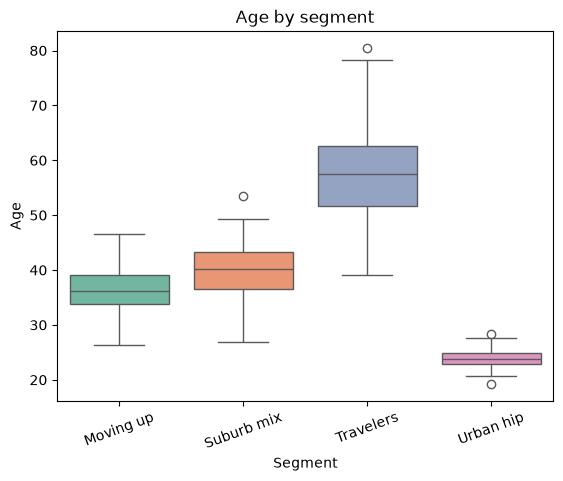

In [42]:
sns.boxplot(data=df, x='Segment', y='age', palette='Set2', order=['Moving up', 'Suburb mix', 'Travelers', 'Urban hip'])
plt.title('Age by segment')
plt.xlabel('Segment')
plt.ylabel('Age')
plt.xticks(rotation=20)
plt.show()


**3 · Two groups.** Are homeowners older than non-owners? Filter the two groups, state H₀ and H₁,
run the test, report t, p and the interval.

- **H₀:** μ_owners = μ_nonowners · **H₁:** μ_owners > μ_nonowners · **Conclusion:** Reject H₀; homeowners are older than non-homeowners, t = 6.68, p = 1.17 × 10^-10, and the 95% CI for the mean age difference is (6.47, 11.88) years.


In [43]:
from scipy import stats

owners_age = df.loc[df['ownHome'] == 'ownYes', 'age']
nonowners_age = df.loc[df['ownHome'] == 'ownNo', 'age']

result = stats.ttest_ind(owners_age, nonowners_age)
mean_diff = owners_age.mean() - nonowners_age.mean()
se = np.sqrt(
    owners_age.var(ddof=1) / len(owners_age) + nonowners_age.var(ddof=1) / len(nonowners_age)
)
df_approx = (
    (owners_age.var(ddof=1) / len(owners_age) + nonowners_age.var(ddof=1) / len(nonowners_age)) ** 2
    / (
        (owners_age.var(ddof=1) / len(owners_age)) ** 2 / (len(owners_age) - 1)
        + (nonowners_age.var(ddof=1) / len(nonowners_age)) ** 2 / (len(nonowners_age) - 1)
    )
)
ci_low = mean_diff - stats.t.ppf(0.975, df_approx) * se
ci_high = mean_diff + stats.t.ppf(0.975, df_approx) * se

print(f"owners mean age = {owners_age.mean():.2f}")
print(f"nonowners mean age = {nonowners_age.mean():.2f}")
print(f"difference = {mean_diff:.2f}")
print(f"t = {result.statistic:.3f}")
print(f"p = {result.pvalue:.3e}")
print(f"95% CI = ({ci_low:.2f}, {ci_high:.2f})")


owners mean age = 46.06
nonowners mean age = 36.89
difference = 9.17
t = 6.680
p = 1.173e-10
95% CI = (6.45, 11.89)


**4 · More than two.** Is age related to segment? Run the ANOVA and read `PR(>F)`.

Age is strongly related to segment: F = 417.10, p < 0.0001. We reject H₀ and conclude that at least one segment has a different mean age.


In [44]:
model_age = ols('age ~ Segment', data=df).fit()
anova_lm(model_age, typ=2)


,sum_sq,df,F,PR(>F)
Segment,39045.783449,3.0,417.10404,6.117331e-106
Residual,9236.346155,296.0,NaN,NaN


**5 · Both at once.** Is age related to ownership **once segment is accounted for**? Two-way ANOVA
with `typ=2`: first with the interaction (`*`), then — if the interaction is not significant —
without it (`+`). What happened to the ownership row, and what does it mean?

The interaction is not significant (p = 0.942), so we drop it. In the additive model, `Segment` remains highly significant (p < 0.0001), while `ownHome` remains non-significant (p ≈ 0.48). This means the age differences are mainly explained by segment membership, not by home ownership after segment is accounted for.


In [45]:
model_int = ols('age ~ Segment * ownHome', data=df).fit()
print('Interaction model:')
print(anova_lm(model_int, typ=2))
print()
print('Additive model:')
model_add = ols('age ~ Segment + ownHome', data=df).fit()
print(anova_lm(model_add, typ=2))


Interaction model:
                       sum_sq     df           F        PR(>F)
Segment          32773.685468    3.0  346.415022  7.702215e-96
ownHome             15.508371    1.0    0.491766  4.836989e-01
Segment:ownHome     12.310861    3.0    0.130125  9.421404e-01
Residual          9208.526923  292.0         NaN           NaN

Additive model:
                sum_sq     df           F        PR(>F)
Segment   32773.685468    3.0  349.506825  9.273518e-97
ownHome      15.508371    1.0    0.496156  4.817499e-01
Residual   9220.837784  295.0         NaN           NaN


**6 · The subscribers.** Do subscribers and non-subscribers differ in income? Test it.

Write the report sentence — **both halves**, as in §2.3.

Subscribers and non-subscribers do not differ in mean income in this sample. The mean income was $45,934 for subscribers and $51,706 for non-subscribers, with t = -1.69 and p = 0.091. We fail to reject H₀: there is not enough evidence that subscriber status is associated with different mean income.


In [46]:
from scipy import stats

sub_yes = df.loc[df['subscribe'] == 'subYes', 'income']
sub_no = df.loc[df['subscribe'] == 'subNo', 'income']

result = stats.ttest_ind(sub_yes, sub_no)
print(f"subYes mean = ${sub_yes.mean():,.0f}")
print(f"subNo mean = ${sub_no.mean():,.0f}")
print(f"t = {result.statistic:.3f}")
print(f"p = {result.pvalue:.3f}")


subYes mean = $45,934
subNo mean = $51,706
t = -1.693
p = 0.091


**7 · No code.** Look at your answers to questions 3 and 5, and at what Part 4 found for income.

In two sentences: what would you tell this company about home ownership as a way of segmenting its
customers?

Home ownership alone looks useful in a simple comparison, but that effect disappears once segment is controlled for, so it is not a strong standalone customer segment. For marketing and customer understanding, segment membership carries much more information about age than home ownership does.


**8 · Put it together.** The company is launching a **family offer** — a discount for families
with children. It can send the offer to only one kind of customer. The manager has two ideas:
choose customers by **subscription** (`subscribe`), or choose them by **segment** (`Segment`). Use
`kids`, the number of children, to decide. Each step uses what the step before it found.

1. **Look.** Make a table of `kids` with count, mean, median and standard deviation — once by
   `subscribe`, once by `Segment`. Then draw a box plot of `kids` by `Segment`, with a title. Which
   column seems to split customers with more children from customers with fewer?
2. **Pick the test.** Use `unique()` on `subscribe` and on `Segment`. How many groups does each have,
   so which test does each one need?
3. **Run.** Run both tests. Report t or F, and p, for each. Do you reject H₀?
4. **Decide.** In two or three sentences for the manager: which column should they use? Which
   segments should get the offer, and which should not? ANOVA does not tell you which segments —
   say what does. For a result that is not significant, write both halves (§2.3).

- **Step 1 — what the table and the plot suggest:** `subscribe` does not separate family size at all; `Segment` does. Travelers have 0 children on average, Urban hip has about 1.1, while Moving up and Suburb mix have about 1.9 children.
- **Step 2 — the test for each column, and why:** `subscribe` has 2 groups, so it needs a two-sample t-test. `Segment` has 4 groups, so it needs a one-way ANOVA.
- **Step 3 — the results:** The `subscribe` comparison gives t = 0.09 and p = 0.923, so we fail to reject H₀. The `Segment` comparison gives F = 50.87 and p = 1.51 × 10^-26, so we reject H₀.
- **Step 4 — for the manager:** Use `Segment`, not `subscribe`, to target the family offer. The offer should go to the two family-heavy segments, `Moving up` and `Suburb mix`, and should not be sent to `Travelers` or `Urban hip`. ANOVA tells us there is a difference; post-hoc comparisons tell us which pairs differ.


/tmp/ipykernel_6332/3031930790.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Segment', y='kids', palette='Set2', order=['Moving up', 'Suburb mix', 'Travelers', 'Urban hip'])


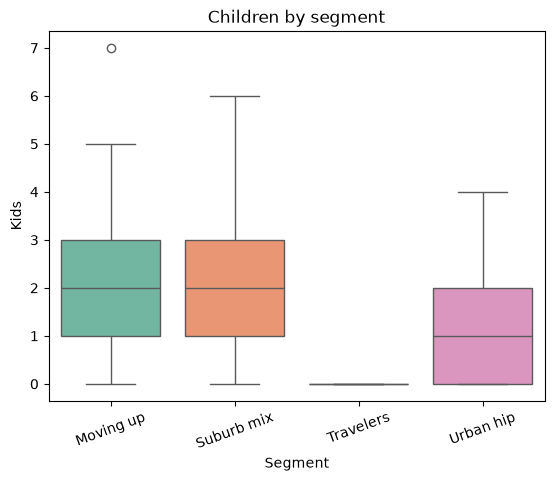

subscribe unique values: <StringArray>
['subNo', 'subYes']
Length: 2, dtype: str
segment unique values: <StringArray>
['Suburb mix', 'Urban hip', 'Travelers', 'Moving up']
Length: 4, dtype: str
subscribe t = -0.096, p = 9.233e-01
              sum_sq     df          F        PR(>F)
Segment   201.784286    3.0  50.874156  1.514030e-26
Residual  391.345714  296.0        NaN           NaN


In [47]:
df.groupby('subscribe')['kids'].agg(['count', 'mean', 'median', 'std']).round(2)
print()
df.groupby('Segment')['kids'].agg(['count', 'mean', 'median', 'std']).round(2)
print()

sns.boxplot(data=df, x='Segment', y='kids', palette='Set2', order=['Moving up', 'Suburb mix', 'Travelers', 'Urban hip'])
plt.title('Children by segment')
plt.xlabel('Segment')
plt.ylabel('Kids')
plt.xticks(rotation=20)
plt.show()

print('subscribe unique values:', df['subscribe'].unique())
print('segment unique values:', df['Segment'].unique())

from scipy import stats
sub_yes = df.loc[df['subscribe'] == 'subYes', 'kids']
sub_no = df.loc[df['subscribe'] == 'subNo', 'kids']
subscribe_res = stats.ttest_ind(sub_yes, sub_no)
print(f"subscribe t = {subscribe_res.statistic:.3f}, p = {subscribe_res.pvalue:.3e}")

model_kids = ols('kids ~ Segment', data=df).fit()
print(anova_lm(model_kids, typ=2))


**9 · Compare the two t tests.**

`ttest_ind` assumes equal population variances by default. Welch's t test uses `ttest_ind(a, b, equal_var=False)` and does not require that assumption.

Ask your AI to explain the difference and when Welch's version is useful. Then rerun the ownership and income comparison in §2.2 with `equal_var=False`.

Report t and p for both versions. Did the p value change? Did the conclusion change? Explain the difference in two or three sentences.

The default pooled-variance t test on income by home ownership gave t = 3.29 and p = 1.12 × 10^-3. Welch's version gave t = 3.27 and p = 1.20 × 10^-3. The p value changed slightly, but the conclusion stayed the same: there is strong evidence of a mean income difference. Welch's test is more robust when group variances are unequal or sample sizes differ, so it is often preferred when the equal-variance assumption is doubtful.


In [48]:
from scipy import stats

owners_income = df.loc[df['ownHome'] == 'ownYes', 'income']
nonowners_income = df.loc[df['ownHome'] == 'ownNo', 'income']

standard = stats.ttest_ind(owners_income, nonowners_income)
welch = stats.ttest_ind(owners_income, nonowners_income, equal_var=False)

print(f"Default t-test: t = {standard.statistic:.3f}, p = {standard.pvalue:.3e}")
print(f"Welch t-test:   t = {welch.statistic:.3f}, p = {welch.pvalue:.3e}")


Default t-test: t = 3.291, p = 1.118e-03
Welch t-test:   t = 3.273, p = 1.195e-03


---
# ✅ Done — hand it in

**No cell is designed to fail.**

1. **Run All**, no red. 2. Save, **commit and sync**. 3. On Moodle: **this notebook**. 4. **Stop your Codespace**.

## What you can now do

- [ ] describe a number across groups with `groupby(...).agg([...])`, including `count`, and draw it with `barplot` and `order=`
- [ ] use `unique()` to count the groups and pick the test
- [ ] **filter rows** with `df.loc[condition, column]` to get one group's values
- [ ] run `ttest_ind` on two groups, and read t, p and the interval for the difference
- [ ] run a one-way ANOVA with `ols` + `anova_lm`, read `PR(>F)`, and say what F is a ratio of
- [ ] recognise a number used as a category — `C(column)` or `.astype(str)` — from the `df` column
- [ ] say what ANOVA does not tell you, and where to look instead
- [ ] run a two-way ANOVA with the interaction (`*`), drop it when it is not significant (`+`), and
  explain how different segment mixes can affect an overall comparison
- [ ] compare the ordinary two sample t test with Welch's version
- [ ] write the two-halves sentence for a result that is not significant
- [ ] put the steps together — look, pick the test, run it, decide — and write the decision for a manager

## Coming up

**Next week is the last teaching week** — regression, which turns "is it related?" into "by how
much?".